# LAB: Chaos Agent: Tools, Lore, Less Questionable Judgments

## Objective

Build a **strict complaint processor** for *NormalObjects* with LangGraph.
Every complaint follows a fixed path, so every answer can be **traced**.

```
intake → validate → investigate → resolve → close
              │
              └──(invalid)──→ reject
```

## 🗺️ Steps

| # | Step | Code |
|---|------|---|
| 1 | Setup and state definition | PROVIDED + YOUR TURN |
| 2 | Define workflow nodes | YOUR TURN |
| 3 | Build the graph | YOUR TURN |
| 4 | Test the workflow | YOUR TURN |
| 5 | Visualize the workflow path | YOUR TURN |
| 6 | Compare with LangChain | YOUR TURN |
| ✅ | `lab_proof.md` | YOUR TURN |

**Submit:** `lab_proof.md` with code, one complaint, evidence, final output, one failure.

| Label | Meaning |
|---|---|
| **PROVIDED** | Run and read it |
| **YOUR TURN** | Replace the `# TODO` lines |
| **OPTIONAL** | Not required |

**Reference:** `langgraph.ipynb`

**Prompt discipline:** use AI to review or debug, not to write your answer.

---
## Step 1: Setup and State Definition

### 1a. Install and import [PROVIDED]

Add `OPENAI_API_KEY=...` to a `.env` file next to this notebook.

In [1]:
# Install required packages (uncomment to run)
# !pip install -U langgraph langchain-openai python-dotenv
%pip install -U langgraph langchain-openai python-dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 575.5/575.5 kB 9.4 MB/s  0:00:00
  Attempting uninstall: langchain-protocol
    Found existing installation: langchain-protocol 0.0.19
    Uninstalling langchain-protocol-0.0.19:
      Successfully uninstalled langchain-protocol-0.0.19
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.6.11
    Uninstalling langchain-core-1.6.11:
      Successfully uninstalled langchain-core-1.6.11
  Attempting uninstall: langchain-openai━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/4 [langchain-core]
    Found existing installation: langchain-openai 1.7.2━━━━━━━ 1/4 [langchain-core]
    Uninstalling langchain-openai-1.7.2:━━━━━━━━━━━━━━━━━━━━━━ 1/4 [langchain-core]
      Successfully uninstalled langchain-openai-1.7.2━━━━━━━━━ 1/4 [langchain-core]
  Attempting uninstall: langgraph╺━━━━━━━━━━━━━━━━━━━ 2/4 [langchain-openai]
    Found existing installation: langgraph 1.2.15━━━━━━━━━━━━━ 2/4 [langchain-openai]
    Uninstalling langgraph-1.2

In [1]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


### 1b. Define the state [YOUR TURN]

Create `ComplaintState(TypedDict)`.

**Required fields** (used by `intake_node`):
- `complaint: str`
- `category: str`
- `workflow_path: List[str]`
- `status: str`

**Add your own:** one field per node result (validation, reason, evidence, resolution, closure).

**Hint:** `TicketState` in `langgraph.ipynb`.

In [2]:
# YOUR TURN: define the state

# TODO: class ComplaintState
class ComplaintState(TypedDict):
    complaint: str
    category: str
    workflow_path: List[str]
    status: str
    is_valid: bool
    validation_reason: str
    evidence: str
    investigation: str
    resolution: str
    closure: str

In [3]:
# YOUR TURN: create a starting state and print it

initial_state = {
       "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
        "category": "",
        "workflow_path": [],
        "status": "new",
        "is_valid": False,
        "validation_reason": "",
        "evidence": "",
        "investigation": "",
        "resolution": "",
        "closure": ""

       }
print(initial_state)

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': '', 'workflow_path': [], 'status': 'new', 'is_valid': False, 'validation_reason': '', 'evidence': '', 'investigation': '', 'resolution': '', 'closure': ''}


**Done when:** your starting state prints all fields.

---
## Step 2: Define Workflow Nodes [YOUR TURN]

Every node must:
1. add its name to `workflow_path`
2. print a log line, e.g. `[VALIDATE] ...`

### 2a. Lore [PROVIDED]

The source for the investigation node.

In [4]:
VALID_CATEGORIES = ["portal", "monster", "psychic", "environmental"]

LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",
    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",
    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",
    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

### 2b. Intake node [PROVIDED]

In [5]:
def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")

    complaint = state["complaint"]

    # Categorize complaint using LLM
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:
- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {complaint}

Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""

    response = llm.invoke([HumanMessage(content=categorization_prompt)])
    category = response.content.strip().lower()

    # Update state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }

    print(f"[INTAKE] Categorized as: {category}")
    return new_state

### 2c. Validation node

Valid if the category is in `VALID_CATEGORIES`. Save the result **and the reason**.

In [6]:
# YOUR TURN: validation node

# TODO: def validate_node(state: ComplaintState) -> ComplaintState:

def validate_node(state: ComplaintState) -> ComplaintState:
    print("[VALIDATE] Checking category...")

    category = state["category"]
    is_valid = category in VALID_CATEGORIES

    if is_valid:
        reason = f"Categoría aceptada: {category}"
    else:
        reason = f"Categoría rechazada: {category}. Categorías válidas: {VALID_CATEGORIES}"

    return {
        **state,
        "is_valid": is_valid,
        "validation_reason": reason,
        "workflow_path": state.get("workflow_path", []) + ["validate"],
        "status": "validated"
    }

### 2d. Investigation node

Use `LORE[category]`. Ask the LLM to answer **only** from that text. Save the lore used as evidence.

In [7]:
# YOUR TURN: investigation node

def investigate_node(state: ComplaintState) -> ComplaintState:
    print("[INVESTIGATE] Reading source...")

    category = state["category"]
    evidence = LORE[category]

    prompt = f"""Answer the complaint using ONLY the source below.
If the source does not contain enough information, say so.
Do not invent facts, predictions, or solutions.

Source:
{evidence}

Complaint:
{state["complaint"]}
"""

    response = llm.invoke([HumanMessage(content=prompt)])

    return {
        **state,
        "evidence": evidence,
        "investigation": response.content,
        "workflow_path": state.get("workflow_path", []) + ["investigate"],
        "status": "investigated"
    }

### 2e. Resolution node

Short fix, based **only** on the investigation.

In [14]:
# YOUR TURN: resolution node

def resolve_node(state: ComplaintState) -> ComplaintState:
    print("[RESOLVE] Preparing resolution...")

    prompt = f"""Write a short resolution using ONLY the investigation below.
Do not add new facts or unsupported actions.
Preserve the uncertainty and scope of the investigation.
Missing prediction information does not mean prediction is impossible.
If no prediction method is provided, say that the available information
does not provide one.
If the investigation does not support a fix, explain the limitation.
Do not claim that any real-world action has been performed.

Investigation:
{state["investigation"]}
"""

    response = llm.invoke([HumanMessage(content=prompt)])

    return {
        **state,
        "resolution": response.content,
        "workflow_path": state.get("workflow_path", []) + ["resolve"],
        "status": "resolved"
    }

### 2f. Closure and rejection nodes

- `close_node`: closing message, status `"closed"`
- `reject_node`: rejection message with the reason, status `"rejected"`

In [9]:
# YOUR TURN: closure + rejection nodes

def close_node(state: ComplaintState) -> ComplaintState:
    print("[CLOSE] Processing completed.")

    return {
        **state,
        "closure": "Complaint processing completed.",
        "workflow_path": state.get("workflow_path", []) + ["close"],
        "status": "closed"
    }


def reject_node(state: ComplaintState) -> ComplaintState:
    print("[REJECT] Complaint rejected.")

    return {
        **state,
        "closure": f"Complaint rejected. Reason: {state['validation_reason']}",
        "workflow_path": state.get("workflow_path", []) + ["reject"],
        "status": "rejected"
    }

In [10]:
# YOUR TURN: test the nodes by hand (no graph yet)

# TODO: s = intake_node(initial_state)
# TODO: s = validate_node(s)
# TODO: ...
# TODO: print(s["workflow_path"])
s = intake_node(initial_state)

print("Category:", s["category"])
print("Path:", s["workflow_path"])
print("Status:", s["status"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal
Category: portal
Path: ['intake']
Status: intake


In [11]:
s = validate_node(s)

print("Valid:", s["is_valid"])
print("Reason:", s["validation_reason"])
print("Path:", s["workflow_path"])
print("Status:", s["status"])

[VALIDATE] Checking category...
Valid: True
Reason: Categoría aceptada: portal
Path: ['intake', 'validate']
Status: validated


In [12]:
s = investigate_node(s)

print("Evidence:", s["evidence"])
print("\nInvestigation:", s["investigation"])
print("\nPath:", s["workflow_path"])
print("Status:", s["status"])

[INVESTIGATE] Reading source...
Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.

Investigation: The source states that portals open when the barrier between worlds is weak and that their timing follows electrical activity, not the clock. Therefore, predicting when the Downside Up portal opens based on a specific time each day is not possible, as it depends on electrical activity rather than a set schedule.

Path: ['intake', 'validate', 'investigate']
Status: investigated


In [13]:
s = resolve_node(s)

print("Resolution:", s["resolution"])
print("\nPath:", s["workflow_path"])
print("Status:", s["status"])

[RESOLVE] Preparing resolution...
Resolution: Resolution: Based on the investigation, it is concluded that predicting the opening of the Downside Up portal cannot be achieved through a fixed daily schedule. The timing of the portal's opening is contingent upon fluctuations in electrical activity, which are not consistent or predictable. Therefore, any attempts to establish a specific time for the portal's opening are inherently limited by this variability in electrical activity.

Path: ['intake', 'validate', 'investigate', 'resolve']
Status: resolved


In [15]:
investigated_state = {
    **s,
    "workflow_path": ["intake", "validate", "investigate"],
    "status": "investigated",
    "resolution": ""
}
s = resolve_node(investigated_state)

print("Resolution:", s["resolution"])
print("\nPath:", s["workflow_path"])
print("Status:", s["status"])

[RESOLVE] Preparing resolution...
Resolution: Resolution:

The investigation indicates that portals open when the barrier between worlds is weak, with their timing influenced by electrical activity rather than a fixed schedule. Consequently, the available information does not provide a reliable method for predicting when the Downside Up portal will open, as it cannot be tied to specific times each day. This limitation underscores the unpredictability of portal openings based on the current understanding of the relationship between electrical activity and portal behavior.

Path: ['intake', 'validate', 'investigate', 'resolve']
Status: resolved


In [16]:
s = close_node(s)

print("Closure:", s["closure"])
print("Path:", s["workflow_path"])
print("Status:", s["status"])

[CLOSE] Processing completed.
Closure: Complaint processing completed.
Path: ['intake', 'validate', 'investigate', 'resolve', 'close']
Status: closed


**Done when:** the path prints `['intake', 'validate', 'investigate', 'resolve', 'close']`.

---
## Step 3: Build the Graph [YOUR TURN]

```
START → intake → validate ──(valid)──→ investigate → resolve → close → END
                     │
                     └──(invalid)──→ reject → END
```

**Hint:** `route_ticket` + `add_conditional_edges` in `langgraph.ipynb`.

In [17]:
# YOUR TURN: routing function

# TODO: def route_after_validation(state: ComplaintState) -> Literal["investigate", "reject"]:
def route_after_validation(
    state: ComplaintState
) -> Literal["investigate", "reject"]:

    if state["is_valid"]:
        return "investigate"

    return "reject"

In [18]:
# YOUR TURN: build and compile the graph

# TODO: workflow = StateGraph(ComplaintState)

# TODO: add all nodes

# TODO: add edges (linear + conditional)

# TODO: app = workflow.compile()
workflow = StateGraph(ComplaintState)

workflow.add_node("intake", intake_node)
workflow.add_node("validate", validate_node)
workflow.add_node("investigate", investigate_node)
workflow.add_node("resolve", resolve_node)
workflow.add_node("close", close_node)
workflow.add_node("reject", reject_node)

workflow.add_edge(START, "intake")
workflow.add_edge("intake", "validate")
workflow.add_conditional_edges("validate", route_after_validation)
workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")

workflow.add_edge("close", END)
workflow.add_edge("reject", END)

app = workflow.compile()

**Done when:** `workflow.compile()` runs without errors.

---
## Step 4: Test the Workflow [YOUR TURN]

Expected: 4 `closed`, 1 `rejected`.

In [19]:
test_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random"  # Should be rejected
]

print("\nTesting workflow with sample complaints...\n")

# YOUR TURN: run every complaint

results = []

for complaint in test_complaints:
    case_state = {
        **initial_state,
        "complaint": complaint,
        "workflow_path": []
    }

    result = app.invoke(case_state)
    results.append(result)

    print("\nComplaint:", result["complaint"])
    print("Category:", result["category"])
    print("Status:", result["status"])
    print("Path:", " → ".join(result["workflow_path"]))
    print("Resolution:", result["resolution"])
    print("Closure:", result["closure"])



Testing workflow with sample complaints...


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal
[VALIDATE] Checking category...
[INVESTIGATE] Reading source...
[RESOLVE] Preparing resolution...
[CLOSE] Processing completed.

Complaint: The Downside Up portal opens at different times each day. How do I predict when?
Category: portal
Status: closed
Path: intake → validate → investigate → resolve → close
Resolution: Resolution:
The investigation indicates that portals open when the barrier between worlds is weak, with their timing influenced by electrical activity rather than a fixed schedule. Consequently, the available information does not provide a method for predicting when the Downside Up portal will open, as it cannot be determined based on specific times each day. This limitation underscores the unpredictability of portal openings and the challenges in establishing a reliable prediction framework.
Closure: Complaint processing completed.

[INTAKE] Processing complain

**Check:** is every claim in one resolution backed by its lore text?

---
## Step 5: Visualize the Workflow Path [YOUR TURN]

1. Draw the graph.
2. Print the path of each complaint: `intake → validate → ...`

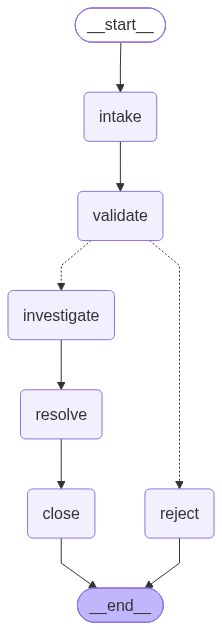

In [20]:
# YOUR TURN: draw the graph

# TODO: display(Image(app.get_graph().draw_mermaid_png()))
display(Image(app.get_graph().draw_mermaid_png()))

In [21]:
# YOUR TURN: print the path of each result

for i, r in enumerate(results, start=1):
    print(f"\nCase {i}: {r['category']} — {r['status']}")
    print(" → ".join(r["workflow_path"]))


Case 1: portal — closed
intake → validate → investigate → resolve → close

Case 2: monster — closed
intake → validate → investigate → resolve → close

Case 3: psychic — closed
intake → validate → investigate → resolve → close

Case 4: environmental — closed
intake → validate → investigate → resolve → close

Case 5: other — rejected
intake → validate → reject


---
## Step 6: Compare with LangChain [YOUR TURN]

Ask the same complaint with **one LLM call** (no graph, no lore). Then fill in the table.

In [22]:
# YOUR TURN: one LLM call

answer = llm.invoke([
    HumanMessage(content=test_complaints[0])
])

print("DIRECT CALL — PORTAL")
print(answer.content)

invalid_answer = llm.invoke([
    HumanMessage(content=test_complaints[4])
])

print("\nDIRECT CALL — INVALID COMPLAINT")
print(invalid_answer.content)

DIRECT CALL — PORTAL
To predict when the Downside Up portal opens, you can follow these steps:

1. **Historical Data**: Gather data on the opening times of the portal over a period of days or weeks. Look for patterns or trends in the times it opens.

2. **Identify Patterns**: Analyze the data for any recurring patterns. For example, does it open at similar times on certain days of the week? Are there specific intervals between openings?

3. **Time Zones**: Ensure you are aware of the time zone in which the portal operates, as this can affect your predictions.

4. **External Factors**: Consider any external factors that might influence the opening times, such as events, holidays, or changes in routine.

5. **Mathematical Modeling**: If you have enough data, you could use statistical methods or algorithms to create a predictive model based on the historical opening times.

6. **Community Insights**: If there is a community or forum related to the Downside Up portal, engage with other use

| | LangGraph | One LLM call |
|---|---|---|
|Same answer every run? |Solo hemos realizado una ejecución de esta comparación. No podemos asegurar repetibilidad; temperature=0 tampoco la garantiza |No comprobado: solo una ejecución |
|Invalid complaint rejected? |Status: rejected |generó una historia humorística |
|Path visible? |workflow_path|No se mostró un registro de nodos |
|Source of each claim? |Tener LORE guardado permite contrastar afirmaciones, pero ya detectamos algunas sin respaldo. |no mostró fuentes verificables. Sugirió recopilar datos históricos y consultar una comunidad, pero no aportó datos, documentos ni referencias concretas |
|Best for which client case? |tramitar solicitudes con reglas |generar ideas creativas |


---
## Extensions [OPTIONAL]

- Parallel investigation
- Retry logic
- Human approval before `resolve`
- Save state with a checkpointer

In [ ]:
# YOUR TURN (optional)

# TODO

---
## ✅ Write `lab_proof.md` [YOUR TURN]

```markdown
# Lab Proof: NormalObjects Complaint Processor

## 1. What I built
## 2. Query
## 3. Evidence (workflow path + log lines + lore used)
## 4. Final output
## 5. Trace (which claim comes from which lore line?)
## 6. Failure or limitation
## 7. LangGraph vs. one LLM call
```

**Before you submit:**
- [ ] No API keys or `.env`
- [ ] Only lab files
- [ ] `lab_proof.md` is the entry point

---
### Troubleshooting

| Problem | Fix |
|---|---|
| Workflow stops at a node | Check node return values and edges |
| Routing doesn't work | Routing function must return a name from the mapping |
| State not updating | Return the updated fields; keys must exist in the state |
| Valid complaint rejected | Print the raw category (dot, capital, newline?) |
| `draw_mermaid_png()` fails | Use `print(app.get_graph().draw_mermaid())` |

In [23]:
portal_result = results[0]

for field in [
    "complaint",
    "category",
    "validation_reason",
    "evidence",
    "investigation",
    "resolution",
    "workflow_path",
    "status"
]:
    print(f"\n{field.upper()}:")
    print(portal_result[field])


COMPLAINT:
The Downside Up portal opens at different times each day. How do I predict when?

CATEGORY:
portal

VALIDATION_REASON:
Categoría aceptada: portal

EVIDENCE:
Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.

INVESTIGATION:
The source states that portals open when the barrier between worlds is weak and that their timing follows electrical activity, not the clock. Therefore, predicting when the Downside Up portal opens based on a specific time each day is not possible, as it depends on electrical activity rather than a set schedule.

RESOLUTION:
Resolution:
The investigation indicates that portals open when the barrier between worlds is weak, with their timing influenced by electrical activity rather than a fixed schedule. Consequently, the available information does not provide a method for predicting when the Downside Up portal will open, as it cannot be determined based on specific times each day. This limitation